# Introduction #

This project explores which Pittsburgh neighborhood is the best based on access to community facilities and safety. We define a strong neighborhood as one that offers useful places for residents to gather, exercise, and participate in community activities while also providing a safe environment.

We began by examining the facilities dataset and identifying which types of facilities would be most useful to residents. Counting every building equally could give neighborhoods credit for storage buildings and offices, so we chose to focus on recreation and community amenities. We also considered counting police and fire stations as a safety measure, but having more emergency facilities does not necessarily mean a neighborhood is safer.

My approach fir this data set uses pandas to clean the data, group facilities by neighborhood, and compare neighborhoods using a scoring system. The facilities analysis can be completed with our current dataset. A combined facilities and safety ranking requires additional incident and population data.

# The Metric #

Our facilities metric measures two features:

Amenity count: The number of active facilities classified as shelters, pools, combined pool and recreation facilities, recreation centers, activity facilities, senior facilities, or community facilities.

Amenity variety: The number of different qualifying facility types in each neighborhood.

We use the provided Pittsburgh facilities CSV, which includes facility names, types, neighborhoods, locations, and an inactive status field. We standardize category names, remove duplicate facility IDs, and include only records explicitly marked as active.

We convert amenity count and variety to comparable scales and calculate a facilities score:

Facilities score = 70% amenity count + 30% amenity variety

These weights reflect our decision to prioritize the number of amenities while also rewarding a range of options. They are project choices rather than an objective definition of neighborhood quality.

For the safety portion, we propose using a neighborhood-level incident dataset covering one consistent time period and a neighborhood population dataset. We would calculate reported incidents per 1,000 residents, with lower rates receiving higher safety scores. If those datasets are obtained, our proposed overall score would give facilities and safety equal weight.

The final result identifies the best neighborhood according to our selected measures. It does not capture every aspect of neighborhood life, such as housing affordability, facility condition, or residents’ personal experiences.

In [1]:
# Import tools for working with data and making graphs.
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV into a pandas table.
facilities = pd.read_csv(
    "fbb50b02-2879-47cd-abea-ae697ec05170.csv"
)

# Remove extra spaces and make text lowercase for consistent categories.
for column in ["neighborhood", "type", "inactive"]:
    facilities[column] = (
        facilities[column].astype("string").str.strip().str.lower()
    )

# Keep only one record per facility ID.
facilities = facilities.drop_duplicates(subset="id")

# Remove records missing a neighborhood or facility type.
facilities = facilities.dropna(subset=["neighborhood", "type"])

# Keep facilities marked "inactive = false"; exclude unknown status.
active = facilities[facilities["inactive"].eq("f")].copy()

# Show how many active facilities belong to each type.
display(active["type"].value_counts())

type
shelter          60
dugout           39
concession       32
storage          29
service          29
firehouse        28
pool             25
office           24
utility          19
activity         18
restrooms        17
senior           16
police           15
medic station    10
salt dome         8
pool/rec          6
rec center        6
pool closed       4
cabin             4
training          4
community         3
recycling         3
vacant            1
Name: count, dtype: Int64

In [2]:
# Define the recreation and community facility types we want to count.
amenity_types = [
    "shelter",
    "pool",
    "pool/rec",
    "rec center",
    "activity",
    "senior",
    "community",
]

# Keep active facilities whose type appears in our list.
amenities = active[active["type"].isin(amenity_types)]

# List every neighborhood in the cleaned dataset alphabetically.
neighborhoods = pd.Index(
    sorted(facilities["neighborhood"].unique()),
    name="neighborhood"
)

# Create a results table with one row per neighborhood.
metrics = pd.DataFrame(index=neighborhoods)

# Count distinct qualifying facilities in each neighborhood.
metrics["amenity_count"] = (
    amenities.groupby("neighborhood")["id"].nunique()
)

# Count the different qualifying facility types in each neighborhood.
metrics["amenity_variety"] = (
    amenities.groupby("neighborhood")["type"].nunique()
)

# Replace missing counts with zero and convert counts to whole numbers.
metrics = metrics.fillna(0).astype(int)

# Select emergency facilities; their presence does not measure safety.
emergency = active[
    active["type"].isin(["police", "firehouse", "medic station"])
]

# Count emergency facilities, assigning zero where none are recorded.
metrics["emergency_facility_count"] = (
    emergency.groupby("neighborhood")["id"]
    .nunique()
    .reindex(metrics.index, fill_value=0)
)

# Show the ten neighborhoods with the largest amenity counts.
display(
    metrics.sort_values("amenity_count", ascending=False).head(10)
)

,amenity_count,amenity_variety,emergency_facility_count
neighborhood,,,
squirrel hill south,15,3,0
highland park,12,3,1
perry north,9,2,1
brookline,7,4,1
mount washington,6,4,1
hazelwood,5,4,1
brighton heights,5,3,1
elliott,4,2,1
morningside,4,2,0


,amenity_count,amenity_variety,emergency_facility_count,facilities_score
neighborhood,,,,
squirrel hill south,15,3,0,92.5
highland park,12,3,1,78.5
brookline,7,4,1,62.7
mount washington,6,4,1,58.0
perry north,9,2,1,57.0
hazelwood,5,4,1,53.3
brighton heights,5,3,1,45.8
south side flats,3,3,1,36.5
sheraden,3,3,1,36.5


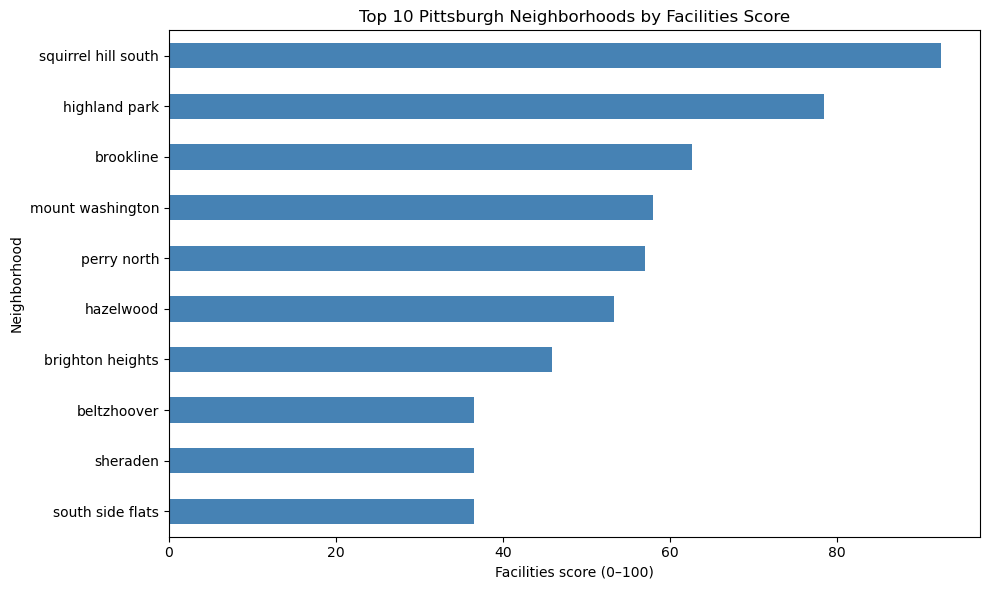

In [3]:
# Define a function that scales values from zero to one.
def normalize(series):
    spread = series.max() - series.min()

    # Give everyone the same value if all measurements are equal.
    if spread == 0:
        return pd.Series(0.5, index=series.index)

    # Make the lowest value zero and the highest value one.
    return (series - series.min()) / spread

# Score facilities using 70% amenity count and 30% variety.
# Emergency facility counts are not included in this score.
metrics["facilities_score"] = 100 * (
    0.70 * normalize(metrics["amenity_count"])
    + 0.30 * normalize(metrics["amenity_variety"])
)

# Rank neighborhoods from highest to lowest facilities score.
ranking = metrics.sort_values("facilities_score", ascending=False)

# Display the top ten, rounded to one decimal place.
display(ranking.head(10).round(1))

# Graph the top ten with the highest score at the top.
ranking.head(10).sort_values("facilities_score").plot.barh(
    y="facilities_score",
    figsize=(10, 6),
    legend=False,
    color="steelblue"
)

# Add a title and axis labels.
plt.title("Top 10 Pittsburgh Neighborhoods by Facilities Score")
plt.xlabel("Facilities score (0–100)")
plt.ylabel("Neighborhood")

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

# Conclusion #

Our analysis identified Squirrel Hill South as the best Pittsburgh neighborhood under our facilities metric. It had 15 qualifying active recreation and community amenities across three facility types, earning a score of 92.5 out of 100.

I do not really have a personal favorite neighborhood because I have only spent time in Oakland. That makes it difficult for me to compare the results with my own experiences. Oakland is the neighborhood I am most familiar with, but that does not necessarily make it the best under our chosen metrics.

This project helped me compare neighborhoods beyond the one I already know. Squirrel Hill South ranked highest because our scoring system emphasized the number and variety of facilities. However, our analysis does not measure facility quality, accessibility, or actual neighborhood safety. The results give me a reason to explore Squirrel Hill South, while also showing that the “best” neighborhood depends on what someone values.